# HW4, round 2: avoid stocks that stop trading, and know your own positions

Author: Ziang Gao

This notebook is a second round on top of `hw4.ipynb`. Round 1 stays unchanged as a record. Here I make **two changes** and I compare the result with the S&P 500 and with round 1.

1. **Survival risk.** In round 1, 42 lots were still open after their 90-day due date because the stock had no more quotes. They were 21% of the final portfolio value. I add size, liquidity and price-level information and a risk model. The risk model gives each stock a chance of being "stuck". The strategy then avoids the riskiest stocks.
2. **Position awareness.** The strategy now sees how old its positions are. It does not buy a stock again when the newest lot in that stock is young. It buys the next best stock instead.

**A fair warning about the result.** Both changes came from looking at the round 1 test result (the stuck lots). So this notebook is **not** a clean out-of-sample test any more. To limit the damage I keep three rules. First, I choose every setting that I can tune on the development years only (2010 to 2015). Second, I fix the settings that I cannot tune before the test and I do not change them after (the risk cut-off and the retraining dates). Third, I run each variant once. I still report the final numbers, but you should read them with this in mind.

## 1. Setup

Same dates and rules as round 1. Starting capital is $1,000,000 and the fee is 5 basis points per side.

In [1]:
import sys, warnings, pickle, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import backtester as bt
import hw4_features as h
import course_data as cd  # lecture code, reused and cited
plt.rcParams["figure.figsize"] = (10, 5)

END = "2026-09-30"
FIRST_TEST_DAY = "2016-04-01"
DEV_START, DEV_END = "2010-01-01", "2015-12-31"
INITIAL_CASH, FEE_BPS = 1_000_000, 5
cfg = bt.Config(initial_cash=INITIAL_CASH, fee_bps=FEE_BPS)

## 2. Load the round 2 data

`build_panel(..., round2=True)` makes the same panel as round 1 and adds these columns.

- `market_cap_proxy`, `log_mcap`: market cap (price times shares) at the quarterly selection date. It was known before the signal date.
- `log_dvol_63`: log of the average daily dollar volume over the last 63 sessions.
- `log_price`: log of the raw closing price. `turnover_63`: dollar volume divided by market cap.
- `entry_price`, `scheduled_exit`: the entry price and the 90-day due date from the label code.
- `stuck` and `resolved_date`: **outcomes, not features.** `stuck` is True when the stock has an entry quote but no exit quote within 5 sessions after the due date. `resolved_date` is the first session when we can know that outcome. They are used only as a training label, and only when `resolved_date` is before the fit date.

I never use `is_active_snapshot` or `delisted_at_snapshot` from the `universe` table. They are written at the end of the data, so they would leak the future. The data guide also says they are audit information and not a predictor.

The same price screen as round 1 removes rows with extreme price behavior.

In [2]:
CACHE = Path("cache/full_panel_v2.pkl")
if CACHE.exists():
    data = pickle.load(open(CACHE, "rb"))
else:
    t0 = time.time()
    panel, wide, bench = h.build_panel(h.DB_FULL, end=END, first_test_day=FIRST_TEST_DAY, verbose=False, round2=True)
    data = {"panel": panel, "wide": wide, "bench": bench}
    CACHE.parent.mkdir(exist_ok=True)
    pickle.dump(data, open(CACHE, "wb"), protocol=4)
    print("built in", round(time.time() - t0), "seconds")
panel, wide, bench = data["panel"], data["wide"], data["bench"]
calendar = wide.index
n_raw = len(panel)
panel = panel[h.screen_mask(panel)].reset_index(drop=True)
dev = panel[panel.date.between(DEV_START, DEV_END)].reset_index(drop=True)
print(f"panel {n_raw:,} rows, {len(panel):,} after the screen | development rows {len(dev):,}")
display(panel[["date", "symbol", "universe_rank", "log_mcap", "log_dvol_63", "log_price", "turnover_63", "stuck", "resolved_date"]].tail(3))

panel 1,664,375 rows, 1,610,567 after the screen | development rows 573,617


,date,symbol,universe_rank,log_mcap,log_dvol_63,log_price,turnover_63,stuck,resolved_date
1610564,2026-09-23,ZTS,333.0,24.136183,19.907500,4.271235,0.014572,False,NaT
1610565,2026-09-23,ZWS,801.0,22.871969,17.684184,3.845456,0.005584,False,NaT
1610566,2026-09-23,ZYME,1637.0,21.392390,16.612376,3.314186,0.008396,False,NaT


## 3. How big is the stuck problem, and when did it happen?

The table counts signals whose outcome is already known (`resolved_date` exists). It shows the share that were stuck, by signal year. The second table shows the share by size bucket (the rank in the quarterly top 2,000 list; rank 1 is the largest company). The third line shows when the last quote of each stock happens.

This is a description of the whole data. I do not use it to tune anything.

In [3]:
lab = panel[panel.entry_price.notna() & panel.resolved_date.notna()].copy()
lab["year"] = lab.date.dt.year
by_year = lab.groupby("year").agg(signals=("stuck", "size"), stuck=("stuck", "sum"))
by_year["stuck %"] = (100 * by_year.stuck / by_year.signals).round(2)
display(by_year.T)

lab["size bucket (rank)"] = pd.cut(lab.universe_rank, [0, 250, 500, 1000, 1500, 2000])
by_size = lab.groupby("size bucket (rank)").agg(signals=("stuck", "size"), stuck=("stuck", "sum"))
by_size["stuck %"] = (100 * by_size.stuck / by_size.signals).round(2)
display(by_size.T)

last_year = wide.apply(lambda c: c.last_valid_index()).dt.year
print("stocks by the year of their last quote:", {"before 2021": int((last_year < 2021).sum()),
      "2021 to 2025": int(last_year.between(2021, 2025).sum()), "2026 (still trading)": int((last_year == 2026).sum())})

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
signals,94065.00,94997.00,96063.00,97672.00,94953.00,95864.00,98607.00,96762.00,96327.00,97991.00,94823.00,93464.00,95012.00,98233.00,97412.00,96665.00,48287.00
stuck,19.00,6.00,12.00,12.00,10.00,11.00,114.00,155.00,35.00,26.00,12.00,618.00,1170.00,1117.00,1227.00,1521.00,804.00
stuck %,0.02,0.01,0.01,0.01,0.01,0.01,0.12,0.16,0.04,0.03,0.01,0.66,1.23,1.14,1.26,1.57,1.67


size bucket (rank),"(0, 250]","(250, 500]","(500, 1000]","(1000, 1500]","(1500, 2000]"
signals,203726.00,202576.00,402453.00,396465.0,381977.00
stuck,307.00,443.00,1698.00,1990.0,2431.00
stuck %,0.15,0.22,0.42,0.5,0.64


stocks by the year of their last quote: {'before 2021': 45, '2021 to 2025': 1073, '2026 (still trading)': 2731}


**What this shows (read this before the models).** In 2010 to 2015 almost no signal is stuck (about 0.01%). From 2021 about 1% are stuck. The reason is the data, not the market. The last table shows that the database holds price history for only a few stocks that stopped trading before 2021. So the development years contain survivors. This has two effects.

- A risk model cannot learn from the development years alone. There are only a few dozen stuck events before the fit date. So I will **retrain the risk model every year** with all outcomes that are finished (the assignment allows retraining if the update rule is fixed in advance).
- Any feature that separates survivors from losers can look good in the development years for the wrong reason. The next section shows an example.

## 4. Does market cap help the return model?

You asked me to try market cap as a feature. I add size and liquidity features (`log_mcap`, `log_dvol_63`, `turnover_63`) to the candidate feature sets. I use the same validation as round 1 (folds 2013, 2014, 2015, rank IC, best mean IC wins).

I also add two sets that include the **price level** (`log_price`). I show them but I exclude them from the choice. Reason: low-priced stocks are mostly penny stocks. Penny stocks that later vanished are missing from the data (section 3). So in the development years the penny stocks that remain look good only because they survived. A model that buys cheap stocks would learn a survivorship effect. I decided this rule after I saw the numbers, so I list it as a judgment call in the README.

In [4]:
folds = cd.date_folds(dev, validation_years=(2013, 2014, 2015))
mom = ["momentum_21", "momentum_63", "momentum_252_21", "mom63_vs_sector", "mom21_vs_sector"]
fin = ["net_margin", "operating_roa", "debt_to_assets", "cash_to_assets", "fcf_to_assets", "accruals_to_assets", "filing_age_days"]
SIZE_LIQ = ["log_mcap", "log_dvol_63", "turnover_63"]
FEATURE_SETS = {
    "A momentum": mom, "B momentum + drawdown": mom + ["drawdown_252"], "C momentum + financials": mom + fin,
    "D all but volatility": [f for f in h.NUMERIC if f != "volatility_63"], "E all features": h.NUMERIC,
    "F C + size and liquidity": mom + fin + SIZE_LIQ, "G momentum + size and liquidity": mom + SIZE_LIQ,
    "H all + size and liquidity": h.NUMERIC + SIZE_LIQ,
    "P1 C + size, liquidity, price level": mom + fin + SIZE_LIQ + ["log_price"],
    "P2 momentum + size, liquidity, price level": mom + SIZE_LIQ + ["log_price"],
}
USES_PRICE_LEVEL = {k for k in FEATURE_SETS if k.startswith("P")}
MODELS = {"Ridge": lambda: Ridge(alpha=100),
          "HGB": lambda: HistGradientBoostingRegressor(max_depth=2, learning_rate=0.03, max_iter=150, min_samples_leaf=500, random_state=0)}

def fit_clipped(model, feats, frame):
    y = frame.target
    lo, hi = y.quantile([0.005, 0.995])
    return cd.make_pipeline(model, feats, include_sector=False).fit(frame[feats], y.clip(lo, hi))

rows = []
for fs_name, feats in FEATURE_SETS.items():
    for m_name, make in MODELS.items():
        for (tr, va), year in zip(folds, (2013, 2014, 2015)):
            fitted = fit_clipped(make(), feats, dev.iloc[tr])
            met = cd.prediction_metrics(dev.iloc[va], fitted.predict(dev.iloc[va][feats]))
            rows.append({"feature set": fs_name, "model": m_name, "year": year, "rank IC": met.mean_daily_rank_IC})
ic = pd.DataFrame(rows).pivot_table(index=["feature set", "model"], columns="year", values="rank IC")
ic["mean"] = ic.mean(axis=1)
ic["uses price level"] = [fs in USES_PRICE_LEVEL for fs, _ in ic.index]
display(ic.sort_values("mean", ascending=False).round(4))
allowed = ic[~ic["uses price level"]]
CHOSEN = allowed["mean"].idxmax()
print("chosen (best mean rank IC, price-level sets excluded):", CHOSEN, "| mean IC", round(allowed["mean"].max(), 4))

year                                                2013    2014    2015  \
feature set                                model                           
P2 momentum + size, liquidity, price level Ridge  0.0695  0.0446  0.0196   
P1 C + size, liquidity, price level        HGB    0.0392  0.0518  0.0284   
                                           Ridge  0.0478  0.0609  0.0066   
P2 momentum + size, liquidity, price level HGB    0.0628  0.0312  0.0095   
C momentum + financials                    Ridge -0.0254  0.0691  0.0023   
F C + size and liquidity                   Ridge -0.0097  0.0292 -0.0074   
C momentum + financials                    HGB   -0.0305  0.0441 -0.0119   
F C + size and liquidity                   HGB   -0.0278  0.0085 -0.0003   
A momentum                                 Ridge -0.0155  0.0090 -0.0291   
H all + size and liquidity                 Ridge -0.0016  0.0152 -0.0499   
D all but volatility                       HGB   -0.0213  0.0278 -0.0518   
                                           Ridge -0.0170  0.0343 -0.0628   
G momentum + size and liquidity            Ridge  0.0049 -0.0203 -0.0332   
E all features                             Ridge -0.0071  0.0222 -0.0638   
                                           HGB   -0.0069  0.0156 -0.0745   
H all + size and liquidity                 HGB   -0.0060  0.0117 -0.0736   
A momentum                                 HGB   -0.0369 -0.0146 -0.0667   
B momentum + drawdown                      Ridge -0.0020 -0.0281 -0.0914   
G momentum + size and liquidity            HGB   -0.0239 -0.0610 -0.0608   
B momentum + drawdown                      HGB   -0.0183 -0.0584 -0.1152   

year                                                mean  uses price level  
feature set                                model                            
P2 momentum + size, liquidity, price level Ridge  0.0446              True  
P1 C + size, liquidity, price level        HGB    0.0398              True  
                                           Ridge  0.0384              True  
P2 momentum + size, liquidity, price level HGB    0.0345              True  
C momentum + financials                    Ridge  0.0153             False  
F C + size and liquidity                   Ridge  0.0040             False  
C momentum + financials                    HGB    0.0006             False  
F C + size and liquidity                   HGB   -0.0065             False  
A momentum                                 Ridge -0.0119             False  
H all + size and liquidity                 Ridge -0.0121             False  
D all but volatility                       HGB   -0.0151             False  
                                           Ridge -0.0152             False  
G momentum + size and liquidity            Ridge -0.0162             False  
E all features                             Ridge -0.0162             False  
                                           HGB   -0.0219             False  
H all + size and liquidity                 HGB   -0.0227             False  
A momentum                                 HGB   -0.0394             False  
B momentum + drawdown                      Ridge -0.0405             False  
G momentum + size and liquidity            HGB   -0.0486             False  
B momentum + drawdown                      HGB   -0.0640             False

chosen (best mean rank IC, price-level sets excluded): ('C momentum + financials', 'Ridge') | mean IC 0.0153


**Decision.** The best sets that use the price level reach a mean IC of about 0.045, but that is the survivorship effect. Among the sets I accept, the best is still the round 1 choice (Ridge on momentum plus financials). Size and liquidity features did **not** improve the return model on the development years. So the return model stays the same as in round 1. The size and liquidity features go to the **risk model** instead, where they matter.

Check the claim about price level. The cell below fits the best price-level model and shows how cheap its top picks are.

In [5]:
p_fs = "P2 momentum + size, liquidity, price level"
tr, va = folds[-1]
probe = fit_clipped(Ridge(alpha=100), FEATURE_SETS[p_fs], dev.iloc[tr])
coef = pd.Series(probe.named_steps["model"].coef_[:len(FEATURE_SETS[p_fs])], index=FEATURE_SETS[p_fs]).sort_values()
display(coef.round(4).to_frame("Ridge coefficient (scaled)"))
d15 = dev[dev.date.between("2015-01-01", "2015-12-31")].copy()
d15["score"] = probe.predict(d15[FEATURE_SETS[p_fs]])
top = d15.groupby("date", group_keys=False).apply(lambda x: x.nlargest(10, "score"))
print(f"2015 top-10 picks of the price-level model: median raw price ${np.exp(top.log_price.median()):.2f} "
      f"against ${np.exp(d15.log_price.median()):.2f} for all eligible stocks")

,Ridge coefficient (scaled)
momentum_63,-0.0231
log_price,-0.0223
mom21_vs_sector,-0.0063
momentum_252_21,-0.0031
turnover_63,-0.0018
log_dvol_63,0.0026
log_mcap,0.0028
momentum_21,0.0062
mom63_vs_sector,0.0190


2015 top-10 picks of the price-level model: median raw price $2.60 against $33.77 for all eligible stocks


## 5. The risk model: which stocks are likely to be stuck?

**Label.** `stuck` (see section 2). **Features** (known at the signal date): size (`log_mcap`), liquidity (`log_dvol_63`, `turnover_63`), price level (`log_price`), risk (`volatility_63`, `drawdown_252`, `momentum_63`) and balance sheet (`debt_to_assets`, `cash_to_assets`, `net_margin`, `operating_roa`). **Model:** a logistic regression (strong regularization, `C=0.1`), with the same clipping, imputing and scaling as the return model. I fixed these choices before the test and did not tune them.

**Update rule (fixed in advance).** Fit on the fit date (2016-03-31) and again on January 1 of each following year. Each fit uses only signals whose outcome was **known before the fit date** (`resolved_date` before the fit date). Each model scores the signals until the next refit. So the model at any date uses only information that existed at that date.

**Gate (fixed in advance).** On each signal date, rank all eligible stocks by predicted risk. The riskiest 25% get no score, so the strategy cannot buy them. I did not tune the 25%.

The table is a check, not a tuning step. For each refit it shows how well the model ranked the stocks that came after it, using outcomes that were known later. `AUC` is the chance that a stuck stock gets a higher risk than a normal stock (0.5 is no skill). `captured` is the share of stuck events inside the riskiest 25%.

In [6]:
RISK_FEATURES = ["log_mcap", "log_dvol_63", "log_price", "turnover_63", "volatility_63", "drawdown_252",
                 "momentum_63", "debt_to_assets", "cash_to_assets", "net_margin", "operating_roa"]
CUT = 0.25                                                    # fixed in advance: avoid the riskiest 25%
FIT_DATE = calendar[calendar.searchsorted(pd.Timestamp(FIRST_TEST_DAY)) - 1]
REFITS = [FIT_DATE] + [pd.Timestamp(f"{y}-01-01") for y in range(2017, 2027)]
known = panel[panel.entry_price.notna()]

def fit_risk(rows):
    return cd.make_pipeline(LogisticRegression(C=0.1, max_iter=500), RISK_FEATURES, include_sector=False).fit(rows[RISK_FEATURES], rows.stuck)

risk_parts, check = [], []
for i, F in enumerate(REFITS):
    nxt = REFITS[i + 1] if i + 1 < len(REFITS) else pd.Timestamp("2100-01-01")
    train_rows = known[known.resolved_date < F]                  # only outcomes that were already known at F
    assert train_rows.resolved_date.max() < F
    model = fit_risk(train_rows)
    window = panel[(panel.date >= F) & (panel.date < nxt)]
    prob = pd.Series(model.predict_proba(window[RISK_FEATURES])[:, 1], index=window.index)
    risk_parts.append(pd.DataFrame({"date": window.date, "symbol": window.symbol, "risk": prob}))
    ev = window[window.resolved_date.notna() & window.entry_price.notna()]
    if ev.stuck.sum() >= 5:
        p_ev = prob.loc[ev.index]
        cut_ev = p_ev.groupby(ev.date).transform(lambda s: s.quantile(1 - CUT))
        check.append({"fit date": F.date(), "stuck events in training": int(train_rows.stuck.sum()),
                      "later signals": len(ev), "later stuck events": int(ev.stuck.sum()),
                      "AUC": roc_auc_score(ev.stuck, p_ev), "stuck % if kept": 100 * ev[p_ev <= cut_ev].stuck.mean(),
                      "stuck % if dropped": 100 * ev[p_ev > cut_ev].stuck.mean(),
                      "captured": ev[p_ev > cut_ev].stuck.sum() / ev.stuck.sum()})
risk = pd.concat(risk_parts).pivot(index="date", columns="symbol", values="risk")
display(pd.DataFrame(check).round(3))
print("risk table", risk.shape, "| first signal", risk.index.min().date(), "| last signal", risk.index.max().date())

,fit date,stuck events in training,later signals,later stuck events,AUC,stuck % if kept,stuck % if dropped,captured
0,2016-03-31,68,75651,65,0.671,0.065,0.148,0.431
1,2017-01-01,176,96762,155,0.583,0.141,0.219,0.342
2,2018-01-01,312,96327,35,0.853,0.014,0.104,0.714
3,2019-01-01,364,97991,26,0.917,0.000,0.106,1.000
4,2020-01-01,399,94823,12,0.138,0.017,0.000,0.000
5,2021-01-01,412,93464,618,0.621,0.377,1.515,0.573
6,2022-01-01,769,95012,1170,0.760,0.588,3.161,0.642
7,2023-01-01,1911,98233,1117,0.694,0.688,2.483,0.546
8,2024-01-01,3035,97412,1227,0.675,0.834,2.537,0.504
9,2025-01-01,4165,96665,1521,0.722,0.888,3.628,0.577


risk table (528, 3320) | first signal 2016-03-31 | last signal 2026-09-23


**How to read it.** Early fits have few events and the numbers are noisy (for example 2020 has only 12 later events). From 2021 on, the model has hundreds or thousands of events. The AUC is about 0.6 to 0.76 and the riskiest quarter holds about half of the later stuck events. That is useful but far from perfect. Stocks that merge or are bought out are hard to predict and may be good stocks.

The table below shows which features push the risk up in the last fit.

In [7]:
last_fit = fit_risk(known[known.resolved_date < REFITS[-1]])
risk_coef = pd.Series(last_fit.named_steps["model"].coef_[0][:len(RISK_FEATURES)], index=RISK_FEATURES).sort_values()
display(risk_coef.round(3).to_frame("logistic coefficient (scaled features); positive = riskier"))

,logistic coefficient (scaled features); positive = riskier
log_dvol_63,-0.553
operating_roa,-0.181
log_price,-0.168
cash_to_assets,-0.113
volatility_63,-0.106
net_margin,0.011
momentum_63,0.101
debt_to_assets,0.162
turnover_63,0.556
drawdown_252,0.562


## 6. Strategy settings, chosen on the development years only

The return model is the round 1 model, so the out-of-sample development scores are the same as in round 1. I backtest 2013 to 2015 with these settings.

- `top_n`: 10, 20 or 40 stocks per entry. `cohort_fraction`: 6% or 10% of NAV per entry.
- `rebuy_wait_days` (new): skip a stock when its newest lot is younger than 30, 45 or 60 days. I also show `None` (no rule) as a reference. I decided before the run that the rule is on, so I choose the best Sharpe among 30, 45 and 60 only.

There are no stuck events in these years (section 3), so the risk gate is not part of this grid. I cannot tune the gate on development data. That is why I fixed it in advance.

In [8]:
fs_name, m_name = CHOSEN
feats = FEATURE_SETS[fs_name]

def to_wide(frame, score):
    return pd.DataFrame({"date": frame.date, "symbol": frame.symbol, "score": np.asarray(score)}).pivot(index="date", columns="symbol", values="score")

parts = []
for (tr, va), year in zip(folds, (2013, 2014, 2015)):
    fitted = fit_clipped(MODELS[m_name](), feats, dev.iloc[tr])
    year_rows = dev[dev.date.between(f"{year}-01-01", f"{year}-12-31")]
    parts.append(to_wide(year_rows, fitted.predict(year_rows[feats])))
dev_scores = pd.concat(parts).sort_index()

anchors = h.signal_dates(calendar, FIRST_TEST_DAY)
first_signal = anchors[anchors >= pd.Timestamp("2012-12-31")][0]
dev_start = calendar[calendar.searchsorted(first_signal, side="right")]

grid = []
for wait in (None, 30, 45, 60):
    for top_n in (10, 20, 40):
        for cohort in (0.06, 0.10):
            strat = bt.TopNStrategy(top_n=top_n, cohort_fraction=cohort, entry_every=5, max_name_weight=0.05, rebuy_wait_days=wait)
            res = bt.run_backtest(wide, dev_scores, strat, dev_start, DEV_END, cfg)
            perf = bt.performance(res.nav.nav)
            buys = res.trades[res.trades.side == "BUY"]
            grid.append({"rebuy_wait_days": "none" if wait is None else wait, "top_n": top_n, "cohort_fraction": cohort,
                         "final_value": perf.final_value, "cagr": perf.cagr, "max_drawdown": perf.max_drawdown,
                         "sharpe": perf.sharpe, "distinct_names": buys.symbol.nunique(), "buys": len(buys)})
grid = pd.DataFrame(grid)
display(grid.sort_values("sharpe", ascending=False).head(10).round(4))
display(grid[grid.rebuy_wait_days == "none"].sort_values("sharpe", ascending=False).head(3).round(4))
best = grid[grid.rebuy_wait_days != "none"].sort_values("sharpe", ascending=False).iloc[0]
TOP_N, COHORT, WAIT = int(best.top_n), float(best.cohort_fraction), int(best.rebuy_wait_days)
ref = bt.performance(bt.benchmark_curve(bench, res.nav.index, INITIAL_CASH))
print(f"chosen: top_n={TOP_N}, cohort_fraction={COHORT}, rebuy_wait_days={WAIT}. Development Sharpe {best.sharpe:.2f}; S&P 500 over the same window {ref.sharpe:.2f}")

,rebuy_wait_days,top_n,cohort_fraction,final_value,cagr,max_drawdown,sharpe,distinct_names,buys
1,none,10,0.10,1.550462e+06,0.1580,-0.2062,0.7838,203,1307
0,none,10,0.06,1.402865e+06,0.1199,-0.1697,0.7503,203,1431
3,none,20,0.10,1.542903e+06,0.1561,-0.2376,0.7308,351,3009
2,none,20,0.06,1.391760e+06,0.1169,-0.1818,0.6817,351,3020
7,30,10,0.10,1.390384e+06,0.1165,-0.2267,0.5974,445,1330
23,60,40,0.10,1.312897e+06,0.0953,-0.1790,0.5781,1333,5320
5,none,40,0.10,1.370589e+06,0.1112,-0.2153,0.5777,574,5360
21,60,20,0.10,1.330474e+06,0.1002,-0.2007,0.5658,888,2680
19,60,10,0.10,1.358308e+06,0.1079,-0.2120,0.5570,539,1330
16,45,40,0.06,1.252832e+06,0.0783,-0.1529,0.5547,1291,6040


,rebuy_wait_days,top_n,cohort_fraction,final_value,cagr,max_drawdown,sharpe,distinct_names,buys
1,none,10,0.10,1.550462e+06,0.1580,-0.2062,0.7838,203,1307
0,none,10,0.06,1.402865e+06,0.1199,-0.1697,0.7503,203,1431
3,none,20,0.10,1.542903e+06,0.1561,-0.2376,0.7308,351,3009


chosen: top_n=10, cohort_fraction=0.1, rebuy_wait_days=30. Development Sharpe 0.60; S&P 500 over the same window 0.94


## 7. Fit the final return model and build the test scores

This is the round 1 step, unchanged. The fit date is the last signal before the first test entry. The model trains on development signals whose 90-day outcome ended before the fit date. It stays fixed for the whole test.

Then I build three score tables.

- `scores_plain`: the return score alone (round 1 behavior).
- `scores_gated`: the return score, with no score for the riskiest 25% on each date (section 5).

In [9]:
train = dev[(dev.label_end < FIT_DATE) & dev.target.notna()]
assert train.date.max() <= pd.Timestamp(DEV_END) and train.label_end.max() < FIT_DATE
final_model = fit_clipped(MODELS[m_name](), feats, train)
test_rows = panel[panel.date >= FIT_DATE]
scores_plain = to_wide(test_rows, final_model.predict(test_rows[feats]))

risk_rank = risk.rank(axis=1, pct=True)                         # per signal date, 1.0 = riskiest
keep = (risk_rank <= 1 - CUT).reindex_like(scores_plain).fillna(False)
scores_gated = scores_plain.where(keep)
print("fit date", FIT_DATE.date(), "| training rows", f"{len(train):,}", "| last outcome ends", train.label_end.max().date())
print(f"scores per date: plain {scores_plain.notna().sum(axis=1).mean():.0f}, gated {scores_gated.notna().sum(axis=1).mean():.0f}")

fit date 2016-03-31 | training rows 573,544 | last outcome ends 2016-03-28
scores per date: plain 1920, gated 1440


## 8. Final test: four variants, one run each

All variants use the same return model, the same fees and the same backtester. They differ in two switches.

| Variant | Risk gate | Rebuy rule | Settings |
|---|---|---|---|
| Round 1 (as submitted) | off | off | top 10, cohort 10% |
| Rebuy rule only | off | on | chosen in section 6 |
| Risk gate only | on | off | chosen in section 6 |
| **Round 2 (both)** | on | on | chosen in section 6 |

First I **reproduce round 1**. The final value must match `results_summary.csv` from round 1. This proves that the new code did not change the old result.

For every variant I also show a **stress value**: the final value if the lots that are still open after their due date (stocks with no more quotes) were worth zero. The data has no payout for such stocks, so the true value is unknown. The reported number values them at their last price. The stress number is a lower bound, not a forecast.

In [10]:
test_start = calendar[calendar.searchsorted(pd.Timestamp(FIRST_TEST_DAY))]
last_px = wide.ffill().iloc[-1]
years = None

def make_strategy(top_n, cohort, wait):
    return bt.TopNStrategy(top_n=top_n, cohort_fraction=cohort, entry_every=5, max_name_weight=0.05, rebuy_wait_days=wait)

def run_variant(scores, top_n, cohort, wait):
    return bt.run_backtest(wide, scores, make_strategy(top_n, cohort, wait), test_start, END, cfg)

def summarize(result):
    perf = bt.performance(result.nav.nav)
    late = result.open_lots[result.open_lots.due_date < pd.Timestamp(END)]
    late_value = float((late.units * late.symbol.map(last_px)).sum())
    final = perf.final_value
    yrs = (result.nav.index[-1] - result.nav.index[0]).days / 365.25
    stress = final - late_value
    sells = result.trades[result.trades.side == "SELL"]
    return pd.Series({"final_value": final, "cagr": perf.cagr, "max_drawdown": perf.max_drawdown, "sharpe": perf.sharpe,
                      "lots past due and still open": len(late), "their share of final value": late_value / final,
                      "stress final value (those lots = 0)": stress, "stress cagr": (stress / INITIAL_CASH) ** (1 / yrs) - 1,
                      "sales more than 10 days late": int(((sells.date - sells.due_date).dt.days > 10).sum())})

V1_SETTINGS = (10, 0.10)
variants = {
    "Round 1 (as submitted)": (scores_plain, *V1_SETTINGS, None),
    "Rebuy rule only": (scores_plain, TOP_N, COHORT, WAIT),
    "Risk gate only": (scores_gated, TOP_N, COHORT, None),
    "Round 2 (both)": (scores_gated, TOP_N, COHORT, WAIT),
}
results = {name: run_variant(*args) for name, args in variants.items()}

old = pd.read_csv("results_summary.csv", index_col=0)
r1 = bt.performance(results["Round 1 (as submitted)"].nav.nav)
assert abs(r1.final_value - old.loc["final_value", "strategy"]) < 1.0, (r1.final_value, old.loc["final_value", "strategy"])
print(f"Round 1 reproduced: final value {r1.final_value:,.0f} matches results_summary.csv ({old.loc['final_value', 'strategy']:,.0f})")

summary = pd.DataFrame({name: summarize(res) for name, res in results.items()})
bench_curve = bt.benchmark_curve(bench, results["Round 2 (both)"].nav.index, INITIAL_CASH)
summary["S&P 500 TR"] = bt.performance(bench_curve)
display(summary.round(4))
summary.to_csv("results_round2.csv")

Round 1 reproduced: final value 3,139,813 matches results_summary.csv (3,139,813)


,Round 1 (as submitted),Rebuy rule only,Risk gate only,Round 2 (both),S&P 500 TR
final_value,3.139813e+06,3.336906e+06,2.876717e+06,2.922679e+06,4.402747e+06
cagr,1.151000e-01,1.216000e-01,1.059000e-01,1.075000e-01,1.516000e-01
max_drawdown,-3.034000e-01,-3.503000e-01,-3.078000e-01,-3.509000e-01,-3.379000e-01
sharpe,5.847000e-01,5.874000e-01,5.395000e-01,5.275000e-01,7.725000e-01
lots past due and still open,4.200000e+01,2.600000e+01,3.000000e+01,2.200000e+01,NaN
their share of final value,2.116000e-01,1.623000e-01,1.475000e-01,1.541000e-01,NaN
stress final value (those lots = 0),2.475381e+06,2.795326e+06,2.452474e+06,2.472412e+06,NaN
stress cagr,9.020000e-02,1.029000e-01,8.920000e-02,9.000000e-02,NaN
sales more than 10 days late,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN


Now the chart. It shows the cumulative return of the S&P 500 total return index, round 1, and round 2. The two partial variants are thin lines.

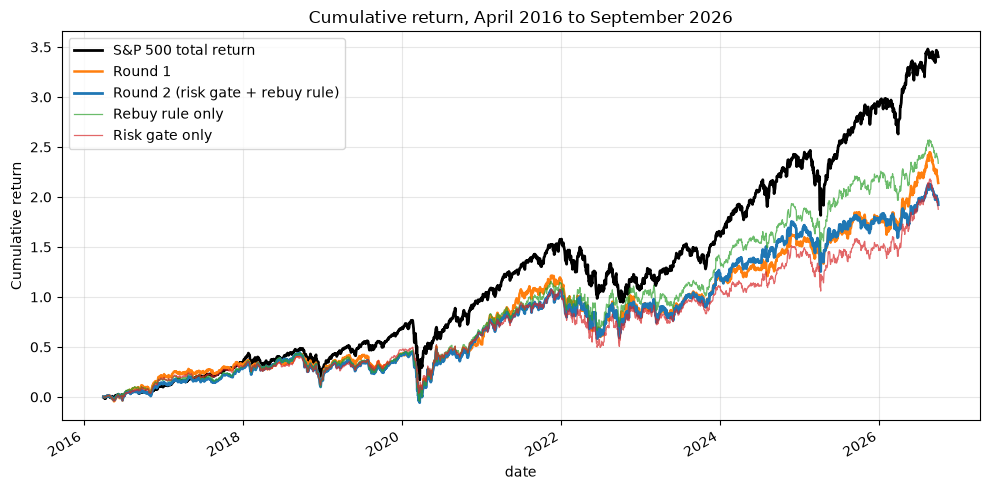

Round 2 minus S&P 500: -1,480,068 dollars; CAGR -4.41%
Round 2 minus round 1: -217,134 dollars; CAGR -0.76%


In [11]:
fig, ax = plt.subplots()
(bench_curve / INITIAL_CASH - 1).plot(ax=ax, label="S&P 500 total return", color="black", lw=2)
(results["Round 1 (as submitted)"].nav.nav / INITIAL_CASH - 1).plot(ax=ax, label="Round 1", color="tab:orange", lw=1.8)
(results["Round 2 (both)"].nav.nav / INITIAL_CASH - 1).plot(ax=ax, label="Round 2 (risk gate + rebuy rule)", color="tab:blue", lw=2)
(results["Rebuy rule only"].nav.nav / INITIAL_CASH - 1).plot(ax=ax, label="Rebuy rule only", color="tab:green", lw=0.9, alpha=0.7)
(results["Risk gate only"].nav.nav / INITIAL_CASH - 1).plot(ax=ax, label="Risk gate only", color="tab:red", lw=0.9, alpha=0.7)
ax.set_title("Cumulative return, April 2016 to September 2026"); ax.set_ylabel("Cumulative return"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("cumulative_return_round2.png", dpi=130); plt.show()
r2 = summary["Round 2 (both)"]; sp = summary["S&P 500 TR"]; r1s = summary["Round 1 (as submitted)"]
print(f"Round 2 minus S&P 500: {r2.final_value - sp.final_value:,.0f} dollars; CAGR {r2.cagr - sp.cagr:+.2%}")
print(f"Round 2 minus round 1: {r2.final_value - r1s.final_value:,.0f} dollars; CAGR {r2.cagr - r1s.cagr:+.2%}")

## 9. Proof that the accounting and the two new rules work

1. `audit` runs the six accounting checks on the round 2 books (the same checks as round 1).
2. **Rebuy rule check.** For every stock, take each pair of consecutive purchases. The later signal date must be at least `rebuy_wait_days` after the earlier purchase date.
3. **Risk gate check.** Every purchase must have a risk rank inside the allowed 75% on its signal date.
4. **Independent NAV.** For three random days I rebuild NAV from the trade log and the price table, without the backtester.
5. The tests in `test_backtester.py` cover the new rule on small markets with answers that can be checked by hand (24 tests).

In [12]:
final = results["Round 2 (both)"]
for name, ok in bt.audit(final, cfg).items():
    print("PASS" if ok else "FAIL", "-", name)

buys = final.trades[final.trades.side == "BUY"].sort_values(["symbol", "date"]).copy()
buys["previous_buy_date"] = buys.groupby("symbol").date.shift(1)
again = buys.dropna(subset=["previous_buy_date"])
gap = (again.signal_date - again.previous_buy_date).dt.days
assert (gap >= WAIT).all(), gap.min()
print(f"PASS - rebuy rule: {len(again):,} repeat purchases, the smallest gap between the old purchase and the new signal is {gap.min()} days (rule: at least {WAIT})")

ranks = np.array([risk_rank.loc[r.signal_date, r.symbol] for r in buys.itertuples()])
assert (ranks <= 1 - CUT + 1e-12).all(), ranks.max()
print(f"PASS - risk gate: {len(buys):,} purchases, the highest risk rank at purchase is {ranks.max():.3f} (limit {1 - CUT:.2f})")

def independent_nav(day):
    day = pd.Timestamp(day)
    done = final.trades[final.trades.date <= day]
    cash = INITIAL_CASH + done.cash_change.sum()
    bought = done[done.side == "BUY"].set_index("lot_id")
    sold = set(done[done.side == "SELL"].lot_id)
    value = sum(r.units * wide[r.symbol].loc[:day].ffill().iloc[-1] for lot_id, r in bought.iterrows() if lot_id not in sold)
    return cash + value

for day in np.random.default_rng(1).choice(final.nav.index[1:], 3, replace=False):
    mine, theirs = independent_nav(day), final.nav.nav.loc[day]
    assert np.isclose(mine, theirs, rtol=1e-9), (day, mine, theirs)
    print(f"NAV on {pd.Timestamp(day).date()}: rebuilt {mine:,.2f} vs backtester {theirs:,.2f}")

PASS - nav = cash + holdings
PASS - cash = start cash + all trade cash flows
PASS - cash never negative (no borrowing, no double spend)
PASS - every buy comes after its signal date
PASS - every sale is on or after 90 calendar days
PASS - every lot is sold once or still open at the end
PASS - rebuy rule: 3,532 repeat purchases, the smallest gap between the old purchase and the new signal is 30 days (rule: at least 30)
PASS - risk gate: 4,420 purchases, the highest risk rank at purchase is 0.750 (limit 0.75)


NAV on 2021-08-11: rebuilt 1,939,057.35 vs backtester 1,939,057.35


NAV on 2021-03-17: rebuilt 1,774,747.17 vs backtester 1,774,747.17
NAV on 2024-03-04: rebuilt 2,320,266.97 vs backtester 2,320,266.97


## 10. What changed in the portfolio

The first table compares how the portfolios were run: number of purchases, number of different stocks bought, how often a stock was bought again within 45 days of its previous purchase, the average share of cash, total fees, and the size of the stocks (median rank in the quarterly list; a higher number means a smaller company) and their price. The second table shows the return in each calendar year.

In [13]:
def portfolio_stats(res):
    b = res.trades[res.trades.side == "BUY"].sort_values(["symbol", "date"]).copy()
    b["gap"] = (b.signal_date - b.groupby("symbol").date.shift(1)).dt.days
    h_ = res.nav.iloc[1:]
    meta = panel.set_index(["date", "symbol"])
    ranks = [meta.universe_rank.get((r.signal_date, r.symbol), np.nan) for r in b.itertuples()]
    return pd.Series({"purchases": len(b), "different stocks": b.symbol.nunique(),
                      "repeat purchases within 45 days": int((b.gap < 45).sum()),
                      "average cash share": (h_.cash / h_.nav).mean(), "total fees": h_.fees.sum(),
                      "median size rank of purchases": float(np.nanmedian(ranks)),
                      "median purchase price ($)": float(b.price.median())})

display(pd.DataFrame({name: portfolio_stats(res) for name, res in results.items()}).round(3))

def yearly(curve):
    last = curve.groupby(curve.index.year).last()
    return last / last.shift(1).fillna(INITIAL_CASH) - 1
yr = pd.DataFrame({"Round 1": yearly(results["Round 1 (as submitted)"].nav.nav), "Round 2": yearly(final.nav.nav), "S&P 500 TR": yearly(bench_curve)})
yr["Round 2 minus Round 1"] = yr["Round 2"] - yr["Round 1"]
yr["Round 2 minus S&P"] = yr["Round 2"] - yr["S&P 500 TR"]
display(yr.round(3))
print("years with round 2 above round 1:", int((yr["Round 2 minus Round 1"] > 0).sum()), "of", len(yr), "| above the S&P 500:", int((yr["Round 2 minus S&P"] > 0).sum()), "of", len(yr))

,Round 1 (as submitted),Rebuy rule only,Risk gate only,Round 2 (both)
purchases,4527.000,4420.000,4570.000,4420.000
different stocks,425.000,839.000,442.000,888.000
repeat purchases within 45 days,3447.000,1511.000,3453.000,1395.000
average cash share,0.124,0.055,0.121,0.055
total fees,61538.229,72400.700,60906.456,68375.896
median size rank of purchases,1010.000,875.500,997.500,837.500
median purchase price ($),53.470,56.115,54.535,56.555


,Round 1,Round 2,S&P 500 TR,Round 2 minus Round 1,Round 2 minus S&P
date,,,,,
2016,0.201,0.128,0.098,-0.072,0.031
2017,0.099,0.134,0.218,0.035,-0.085
2018,-0.107,-0.083,-0.044,0.024,-0.039
2019,0.212,0.205,0.315,-0.007,-0.110
2020,0.070,0.154,0.184,0.084,-0.030
2021,0.424,0.265,0.287,-0.159,-0.022
2022,-0.151,-0.117,-0.181,0.034,0.064
2023,0.188,0.231,0.263,0.043,-0.032
2024,0.144,0.162,0.250,0.018,-0.088


years with round 2 above round 1: 6 of 11 | above the S&P 500: 2 of 11


### Stocks that are still stuck at the end

This is the same table as in round 1, for round 2. It lists the open lots that are past their due date, by value.

In [14]:
late = final.open_lots[final.open_lots.due_date < pd.Timestamp(END)].copy()
late["value"] = late.units * late.symbol.map(last_px)
late["last_quote"] = late.symbol.map(lambda s: wide[s].last_valid_index())
print(f"round 2: {len(late)} lots are past due and still open, value {late.value.sum():,.0f} ({late.value.sum() / final.nav.nav.iloc[-1]:.2%} of final value)")
display(late.sort_values("value", ascending=False)[["symbol", "entry_date", "due_date", "last_quote", "value"]].head(6))
ev = final.events.event.value_counts().to_frame("count")
display(ev)

round 2: 22 lots are past due and still open, value 450,266 (15.41% of final value)


,symbol,entry_date,due_date,last_quote,value
21,VSCO,2026-05-08,2026-08-06,2026-07-13,43882.256779
19,REVG,2025-11-28,2026-02-26,2026-01-30,30315.786792
20,CIVI,2025-12-19,2026-03-19,2026-01-29,27972.133864
18,HES,2025-05-02,2025-07-31,2025-07-18,27903.032835
16,SWN,2024-07-30,2024-10-28,2024-09-30,25120.985694
12,SEAS,2024-02-21,2024-05-21,2024-03-12,25080.545596


,count
event,
sale_delayed_no_quote,15126
stale_mark_over_limit,17


### How much money sat frozen?

A stuck lot cannot be sold (no quote), so its money cannot be used again. This idle money is a cost even when the last price was fair. The table shows the average share of the portfolio value that sat in past-due lots during the test, and the share at the end. The value of each lot is taken at its last known price from its due date on (an approximation).

In [15]:
def frozen_share(res):
    nav = res.nav.nav
    late = res.open_lots[res.open_lots.due_date < pd.Timestamp(END)].copy()
    late["value"] = late.units * late.symbol.map(last_px)
    frozen = pd.Series(0.0, index=nav.index)
    for r in late.itertuples():
        frozen[frozen.index >= r.due_date] += r.value
    return (frozen / nav).iloc[1:]

fz = {name: frozen_share(res) for name, res in results.items()}
display(pd.DataFrame({name: {"average share of value frozen": s.mean(), "share frozen at the end": s.iloc[-1],
                             "highest share on any day": s.max()} for name, s in fz.items()}).round(3))

,Round 1 (as submitted),Rebuy rule only,Risk gate only,Round 2 (both)
average share of value frozen,0.073,0.042,0.054,0.041
share frozen at the end,0.212,0.162,0.147,0.154
highest share on any day,0.266,0.162,0.186,0.157


## 11. Findings

### Did round 2 beat the S&P 500? Did it beat round 1?

No to both. Round 2 (risk gate and rebuy rule together) ended with $2,922,679 (CAGR 10.8%, maximum drawdown -35.1%, Sharpe 0.53). The S&P 500 total return index ended with $4,402,747 (CAGR 15.2%, -33.8%, 0.77). Round 2 is $1,480,068 behind the index. Round 1 ended with $3,139,813, so round 2 is also $217,134 behind round 1. Round 2 was above round 1 in 6 of 11 calendar years and above the S&P 500 in 2 of 11.

| | Final value | CAGR | Max drawdown | Sharpe | Past-due lots at the end | Final value if those lots = 0 |
|---|---|---|---|---|---|---|
| Round 1 | $3,139,813 | 11.5% | -30.3% | 0.58 | 42 | $2,475,381 |
| Rebuy rule only | $3,336,906 | 12.2% | -35.0% | 0.59 | 26 | $2,795,326 |
| Risk gate only | $2,876,717 | 10.6% | -30.8% | 0.54 | 30 | $2,452,474 |
| Round 2 (both) | $2,922,679 | 10.8% | -35.1% | 0.53 | 22 | $2,472,412 |
| S&P 500 TR | $4,402,747 | 15.2% | -33.8% | 0.77 | | |

### What each change did

- **Risk gate.** It works as designed. Out of sample, the riskiest 25% held about 50% to 64% of the later stuck events from 2021 on (AUC 0.62 to 0.76). It cut the stuck lots from 42 to 30 and it lowered the share of value frozen in such lots (21.2% to 14.7% at the end). But the final value fell by $263,096. The gate removes about a quarter of the stocks, so the picks change, and I cannot show that the loss is more than noise.
- **Rebuy rule.** Alone, it raised the final value by $197,093. I do not trust this as evidence for the rule. On the development years, the rule lowered the Sharpe ratio (0.78 without it, 0.60 with the best setting). In the test, the gain probably comes from less idle cash (12.4% to 5.5% of the portfolio) and more stocks (839 instead of 425), because the 5% cap no longer leaves part of each budget unspent. More invested money raised the return and also the drawdown (-30.3% to -35.0%).
- **Together.** The two effects did not add up. The result is below round 1.

### Why the premise needs care

I started from the idea that stocks that stop trading cause much of the loss. The data does not support a strong version of this.

- The stuck lots are valued at their last price, so they are not booked as losses. The cost is idle money, because a lot with no quote cannot be sold. On average 7.3% of the round 1 portfolio sat in such lots (4.1% in round 2). That probably explains only a small part of the 3.7 point CAGR gap to the S&P 500.
- Several stuck names look like takeover targets (for example HES and SWN, as far as I know), and the data guide says an inactive flag can mean a rename. A takeover usually pays close to the last price. The zero-value case is a lower bound that is too harsh for such stocks.
- The main reason for the gap to the index is the same as in round 1. The return signal is weak. The return model did not change.

### What I learned about the data

- The development years hold almost no stuck events (0.01% of signals), but from 2021 about 1% are stuck. The database keeps price history for recent delistings only (45 of 3,849 stocks have a last quote before 2021). So a model cannot learn this risk from 2010 to 2015, and the development years hold survivors.
- This survivorship bias can fool a model. Sets with the price level reached a mean rank IC of 0.045 against 0.015, but they buy penny stocks (median price of the 2015 picks $2.60 against $33.77). I excluded the price level from the return model. That was a judgment call after I saw the numbers.
- Market cap and liquidity did not improve the return model on the development years. In the risk model, the single features point the way one expects (a bigger company has fewer stuck events: 0.15% for ranks 1 to 250 against 0.64% for ranks 1,500 to 2,000). The signs in the multi-feature model mix, because market cap, volume and turnover are closely related.

### Limits

- **The test is not clean.** Both changes came from the round 1 test result. I tuned only on development years and fixed the other settings in advance, but the number of changes I tried is not zero.
- **Noise.** In round 1, random scores earned $2.68M and the model $3.14M. Differences of $200,000 are in that range. I did not measure the noise of round 2.
- **Risk model settings.** The 25% cut-off, the feature list and `C=0.1` were not tuned. Other values may be better or worse.
- **Zero-value and frozen-money numbers** are bounds and approximations. The data has no payout table.
- **Survivorship in training data** affects the return model too, not only the risk model.

### What I would try next

1. Handle a lot with no quote as a clear, stated assumption, for example sell it at its last quote after 20 sessions without a quote, and report this as a separate case next to the strict result. This would free the idle money without a hidden choice.
2. Retrain the return model every year, using only finished outcomes, and test the update rule on the development years first.
3. Measure the noise: run the strategy on many random start dates or bootstrap the entry cohorts, and show a range for each variant.
4. Test a softer gate, such as a score penalty in proportion to the predicted risk, instead of a hard cut of 25%.

### AI assistance

Claude, an AI assistant from Anthropic, helped write the code of round 2 (`hw4_features.py` additions, the `rebuy_wait_days` rule in `backtester.py`, its tests, and this notebook). The two changes were my requests. I used the results above only as reported by the code.